In [1]:
# import libaries
import numpy as np 
import  pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
import sqlite3
import os

In [2]:
# Import Data

In [3]:
conn = sqlite3.connect(r"C:\Users\vkesh\customer_churn.db")

sql_query = """
SELECT name
FROM sqlite_master
WHERE type='table'
"""
tables = pd.read_sql_query(sql_query, conn)

for table_name in tables['name']:
    df = pd.read_sql_query(
        f'SELECT * FROM "{table_name}"',
        conn
    )
    globals()[f"df_{table_name}"] = df
    print(f"Created dataframe: df_{table_name}")

print(tables)
conn.close()

Created dataframe: df_db_customer
Created dataframe: df_db_subscription
Created dataframe: df_db_support
              name
0      db_customer
1  db_subscription
2       db_support


In [4]:
# Print table names and col. names

conn = sqlite3.connect('customer_churn.db')

for table_name in tables['name']:
    print(f"\n Table Name: {table_name}")

    # Get COL Info
    cols_query = f"PRAGMA table_info({table_name});"
    cols = pd.read_sql(cols_query, conn)
    print("cols:")
    print(cols['name'].tolist())

conn.close()


 Table Name: db_customer
cols:
['customerid', 'name', 'country', 'state', 'gender', 'dob', 'interests', 'pincode']

 Table Name: db_subscription
cols:
['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score']

 Table Name: db_support
cols:
['customerid', 'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment']


In [5]:
print(tables)

              name
0      db_customer
1  db_subscription
2       db_support


In [6]:
df_db_customer.head()

,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,None,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,None,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None


In [7]:
# Data Cleaning

In [8]:
df_db_customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   customerid  21 non-null     object
 1   name        21 non-null     object
 2   country     18 non-null     object
 3   state       21 non-null     object
 4   gender      21 non-null     object
 5   dob         21 non-null     object
 6   interests   4 non-null      object
 7   pincode     0 non-null      object
dtypes: object(8)
memory usage: 1.4+ KB


In [9]:
# 1. dorp col.- Interest and pincode
# 2. rename col. - name
# 3. change dob datatype
# 4. data standari
# 5. fix missing value in country

In [10]:
# Rename col. Name

df_db_customer.rename(columns = {'name' : 'customer_name'}, inplace = True)
print(df_db_customer)

    customerid customer_name country          state  gender  \
0   0002-ORFBO        keshav   India    Maharashtra    Male   
1   0003-MKNFE        raghav   India      Karnataka    Male   
2   0004-TLHLJ        lalita   India          Delhi  Female   
3   0011-IGKFF         mohan   India       Nagaland    Male   
4   0013-EXCHZ          mira   India          Delhi  Female   
5   0013-MHZWF         durga    None          Delhi   Women   
6   0013-SMEOE          mina   India      Meghalaya  Female   
7   0014-BMAQU         madan   India      Rajasthan    Male   
8   0015-UOCOJ          maya    None      Kathmandu   Women   
9   0016-QLJIS         arjun   Nepal      Kathmandu    Male   
10  0017-DINOC         shiva   India    Maharashtra     Men   
11  0017-IUDMW     rangadevi   India      Karnataka  Female   
12  0018-NYROU        chitra    None      Telangana  Female   
13  0019-EFAEP          raju   India      Meghalaya  Female   
14  0019-GFNTW        Madhav   India  Uttar Pradesh    

In [11]:
# Drop cols. name 

df_db_customer.drop(df_db_customer.columns[-2:], axis = 1, inplace = True)


In [12]:
# change DATA_TYPE

df_db_customer['dob'] = pd.to_datetime(df_db_customer['dob'])

In [13]:
# Data Standarization 

df_db_customer['gender'] = df_db_customer['gender'].replace({'Men' : 'Male' , 'Women' : 'Female'})

In [14]:
# Missing Value

df_db_customer[df_db_customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob
5,0013-MHZWF,durga,None,Delhi,Female,1988-12-10
8,0015-UOCOJ,maya,None,Kathmandu,Female,1985-07-07
12,0018-NYROU,chitra,None,Telangana,Female,2004-12-01


In [15]:
# country and state into unique value pair
state_country_mapping = (
    df_db_customer.dropna(subset=['country'])
    .set_index('state')['country']
    .to_dict()
)

df_db_customer['country'] = (
    df_db_customer['country'].fillna(
        df_db_customer['state'].map(state_country_mapping)
    )
)

In [16]:
df_db_customer[df_db_customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob


In [17]:
df_db_customer.drop(df_db_customer.columns[-1:], axis = 1, inplace = True)

In [18]:
### Task Performing on New Table 

In [19]:
df_db_subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               21 non-null     object 
 1   subscription_start_date  21 non-null     object 
 2   subscription_type        21 non-null     object 
 3   renewal_date             21 non-null     object 
 4   plan_type                21 non-null     object 
 5   contract_type            21 non-null     object 
 6   cancellation_date        6 non-null      object 
 7   cancellation_reason      6 non-null      object 
 8   monthly_charges          21 non-null     float64
 9   cltv                     21 non-null     int64  
 10  churn_score              21 non-null     int64  
dtypes: float64(1), int64(2), object(8)
memory usage: 1.9+ KB


In [20]:
date_col = ['subscription_start_date', 'renewal_date', 'cancellation_date']
df_db_subscription[date_col] = df_db_subscription[date_col].apply(pd.to_datetime)


In [21]:
df_db_support.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      9 non-null      object
 1   complaint_date  9 non-null      object
 2   escalations     9 non-null      object
 3   csat_score      9 non-null      int64 
 4   col_1           0 non-null      object
 5   comment         4 non-null      object
dtypes: int64(1), object(5)
memory usage: 560.0+ bytes


In [22]:
df_db_support.drop(df_db_support.columns[-2:], axis = 1, inplace = True)

In [23]:
df_db_support['complaint_date'] = pd.to_datetime(df_db_support['complaint_date'])

In [24]:
### FEATURE ENGINEERING AND DATA ANALYSIS ###

In [25]:
## Churn Flag

df_db_subscription['churn_flag'] = np.where(df_db_subscription['cancellation_date'].notna(),1,0)

In [26]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,34,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,None,22.99,1725,8,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1


In [27]:
 df_db_support['complaint_count'] = df_db_support.groupby('customerid')['customerid'].transform('count')

In [28]:
df_db_support = df_db_support.sort_values('complaint_date').drop_duplicates('customerid' , keep = 'last')

In [29]:
# MERGE DATA_FRAME

df = df_db_subscription.merge(df_db_customer, on = 'customerid', how = 'left').merge(df_db_support,
                                                                                on = 'customerid', how = 'left')

In [30]:
df.shape


(21, 20)

In [31]:
df.to_csv('exported_data.csv', index = False)

In [32]:
## Data Analysis

In [33]:
# 1. Churn Rate

In [34]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='object')

In [35]:
churn_rate = df['churn_flag'].mean()*100
print("Churn Rate = " , round(churn_rate,2),"%")

Churn Rate =  28.57 %


In [36]:
# 2. Retention Rate
rentention_rate = 100- churn_rate
print("Retention Rate = " , round(rentention_rate,2),"%")

Retention Rate =  71.43 %


In [37]:
# 3. Churn by Plan Type

churn_by_plan = (df.groupby('plan_type')['churn_flag'].mean().mul(100).round(2).reset_index(name= 'churn_rate_pct'))
print(churn_by_plan)

  plan_type  churn_rate_pct
0     Basic           60.00
1   Premium           14.29
2  Standard           22.22


In [38]:
# 4. a. Churn by state + sum(revenue) & count of users

churn_by_state = (
    df.groupby('state')['churn_flag'].mean().mul(100).round(2)
    .reset_index(name='churn_rate_pct')
    .merge(
        df.groupby('state')['monthly_charges'].sum().reset_index(name='total_revenue'),
        on='state'
    )
    .merge(
        df.groupby('state')['customerid'].count().reset_index(name='user_count'),
        on='state'
    )
)

print(churn_by_state)

           state  churn_rate_pct  total_revenue  user_count
0          Delhi           25.00          52.96           4
1      Karnataka          100.00          20.98           2
2      Kathmandu            0.00          20.98           2
3    Maharashtra            0.00          50.97           3
4      Meghalaya           66.67          42.97           3
5       Nagaland            0.00          22.99           1
6      Rajasthan            0.00          36.98           2
7      Telangana           50.00          30.98           2
8  Uttar Pradesh            0.00         115.98           2


In [39]:
# 4. b. Churn by subs. type + sum(revenue) & count of users

churn_by_subs = (
    df.groupby('plan_type')['churn_flag'].mean().mul(100).round(2)
    .reset_index(name="churn_rate_pct")
    .merge(
        df.groupby('plan_type')['monthly_charges'].sum().reset_index(name='total_revenue'),
        on= 'plan_type'
    )
    .merge(
        df.groupby('plan_type')['customerid'].count().reset_index(name='user_count'),
        on= 'plan_type'
    )
)
print(churn_by_state) 

           state  churn_rate_pct  total_revenue  user_count
0          Delhi           25.00          52.96           4
1      Karnataka          100.00          20.98           2
2      Kathmandu            0.00          20.98           2
3    Maharashtra            0.00          50.97           3
4      Meghalaya           66.67          42.97           3
5       Nagaland            0.00          22.99           1
6      Rajasthan            0.00          36.98           2
7      Telangana           50.00          30.98           2
8  Uttar Pradesh            0.00         115.98           2


In [40]:
# 5. ARPU - Avg Revenue Per User
arpu = df['monthly_charges'].mean()
print('ARPU = ', round(arpu,2))

ARPU =  18.85


In [41]:
# 6. Avg Customer Tenure
# count of days users has used our service : cancel date else current date 

today = pd.Timestamp.today()

df['tenure_days'] = np.where(
    df['cancellation_date'].notna(),
    (df['cancellation_date'] - df['subscription_start_date']).dt.days,
(today - df['subscription_start_date']).dt.days
)

avg_tenure = df['tenure_days'].mean()
print("Avg_Tenure (Days) = ", round(avg_tenure),0)

Avg_Tenure (Days) =  1569 0


In [42]:
# 7. Revenue at Risk - Revenue lost from churned users

revenue_at_risk = df.loc[df['churn_flag']==1, 'monthly_charges'].sum()
print("Revenue at Risk (Rs 'K') = ", revenue_at_risk)

Revenue at Risk (Rs 'K') =  73.94


In [43]:
# 8. Esclation Rate 
escalation_rate = (df['escalations']=='Y').mean()*100
print("Esclation Rate = " , round(escalation_rate, 2),"%")

Esclation Rate =  19.05 %


In [44]:
# 9. Avg Complaint Rate Per User
complaint_avg = df['complaint_count'].sum() / df['customerid'].nunique()
print("Avg Complaints Per User = ", round(complaint_avg,2))

Avg Complaints Per User =  0.43


In [45]:
# 10. Correlation Esc VS Churn

df['escalations'] = np.where(df['escalations'] == 'Y', 1, 0)
# Encoding string to int type

corr_df = df[['escalations', 'churn_flag']].dropna()

correlation = corr_df['escalations'].corr(corr_df['churn_flag'])

print("Correlation (Esc VS Churn) =", round(correlation, 2))

Correlation (Esc VS Churn) = 0.77


In [46]:
df.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,churn_flag,customer_name,country,state,gender,complaint_date,escalations,csat_score,complaint_count,tenure_days
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,...,0,keshav,India,Maharashtra,Male,NaT,0,NaN,NaN,2052.0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,1,raghav,India,Karnataka,Male,2024-08-28,1,10.0,2.0,1501.0
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,...,0,lalita,India,Delhi,Female,NaT,0,NaN,NaN,1437.0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,None,22.99,1725,...,0,mohan,India,Nagaland,Male,NaT,0,NaN,NaN,2727.0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,...,1,mira,India,Delhi,Female,2024-01-20,1,20.0,1.0,419.0


In [47]:
# Churn Risk  
conditions = [
    (df['churn_score'] < 50),
    (df['churn_score']>=50) & (df['churn_score'] <70),
    (df['churn_score'] >= 70)
]

choices = ['low', 'med','high']

df['churn_risk'] = np.select(conditions, choices , default = 'unknown')


In [48]:
df['churn_risk']

0      low
1     high
2      low
3      low
4     high
5      low
6     high
7      low
8      low
9      low
10     low
11    high
12     low
13    high
14     low
15     med
16     med
17     low
18    high
19     low
20     low
Name: churn_risk, dtype: object

In [49]:
### DATA VISUALIZATION  ####

In [50]:
# BY Matplotlib

In [51]:
df_visual = df.copy()

Text(0, 0.5, 'Churned Customer')

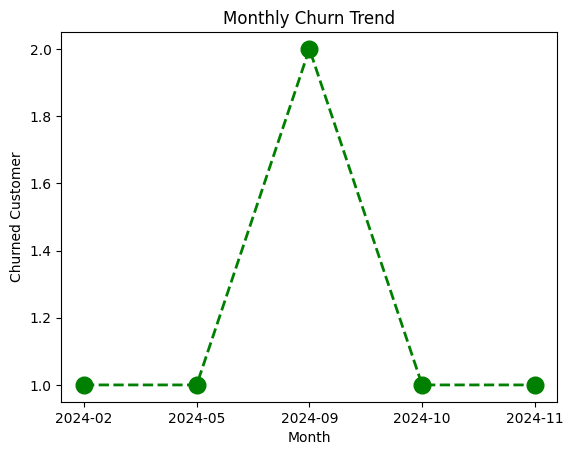

In [58]:
# 1. Monthly churn Trend(Time Series KPI)

df_visual['cancellation_month'] = df_visual['cancellation_date'].dt.to_period('M')

churn_trend = df_visual[df_visual['churn_flag'] == 1].groupby('cancellation_month').size()

plt.plot(churn_trend.index.astype(str), churn_trend.values, color = 'green' , marker = 'o' , linestyle= 'dashed' , linewidth=2, markersize=12)

plt.title('Monthly Churn Trend')
plt.xlabel('Month')
plt.ylabel('Churned Customer')

<BarContainer object of 3 artists>

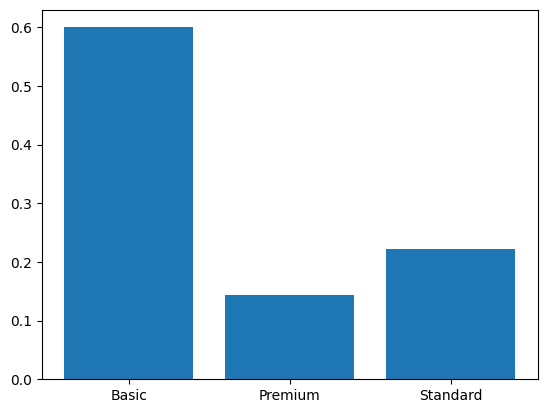

In [61]:
# 2. Churn by Plan Type

churn_plan = df_visual.groupby('plan_type')['churn_flag'].mean()

plt.bar(churn_plan.index, churn_plan.values)

<BarContainer object of 9 artists>

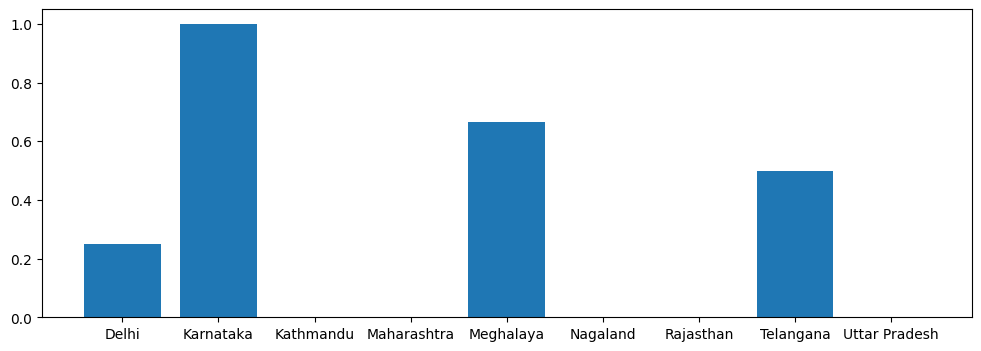

In [63]:
# 3. By state

churn_state = df_visual.groupby('state')['churn_flag'].mean()

plt.figure(figsize = (12,4))
plt.bar(churn_state.index, churn_state.values)

In [65]:
# By Seaborn 

In [67]:
# Encoding

df_encoded = df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk','escalations']]

categorial_cols = ['plan_type', 'contract_type', 'churn_risk']

for col in categorial_cols:
    df_encoded[col] = df_encoded[col].astype('category').cat.codes


C:\Users\vkesh\AppData\Local\Temp\ipykernel_1608\1102312370.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_encoded[col] = df_encoded[col].astype('category').cat.codes
C:\Users\vkesh\AppData\Local\Temp\ipykernel_1608\1102312370.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_encoded[col] = df_encoded[col].astype('category').cat.codes
C:\Users\vkesh\AppData\Local\Temp\ipykernel_1608\1102312370.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try 

<Axes: >

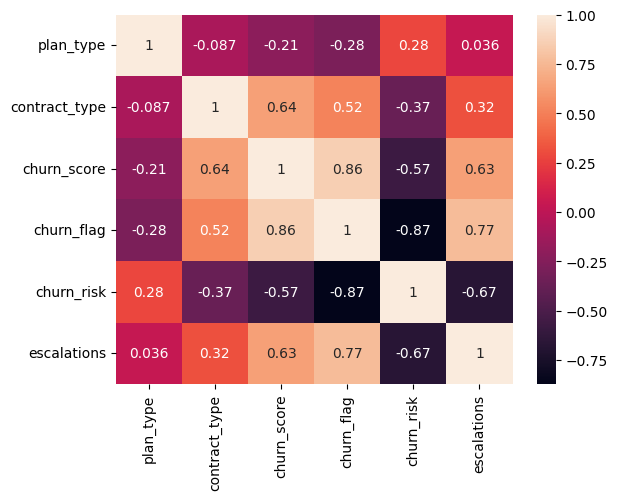

In [69]:
sns.heatmap(df_encoded.corr(), annot = True)

In [70]:
## PIVOT TABLE

In [82]:
pd.pivot_table(
    df_visual,
    index='plan_type',
    values='churn_flag',
    aggfunc = 'mean',
).reset_index()

,plan_type,churn_flag
0,Basic,0.600000
1,Premium,0.142857
2,Standard,0.222222


In [83]:
## Working with Sql

In [84]:
# create database in sql

In [85]:
conn = sqlite3.connect('test_database.sqlite')

conn.execute("CREATE TABLE users(first_name TEXT, country TEXT, budget INTEGER)")

## coomit and save

conn.commit()

In [89]:
## insert data

cursor = conn.cursor()

cursor.execute(
    """
    INSERT INTO users VALUES (
        "Keshav", "India", 4000
    )
    """
)

conn.commit()